<a href="https://colab.research.google.com/github/ThomasAlbin/Space-Science-With-Python/blob/main/2026/leonids_radiant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Leonids: Computing a Meteor Shower's Radiant with SPICE

Every November, the Leonid meteors seem to burst from one small patch of sky in the constellation Leo: the **radiant**. In 1966 they came at a peak rate of about 15,000 meteors per hour; in 2026, the International Meteor Organization (IMO) expects about 15. Every one of them is a dust grain from comet **55P/Tempel–Tuttle**.

*Can we compute that point in the sky from nothing but the comet's orbit?*

The idea in three steps:

1. **Where Earth meets the dust.** The grains move along the comet's orbit. On the night of the shower's peak, we look for the point on that orbit closest to Earth.
2. **The relative velocity.** There, a grain moves with the comet's orbital velocity $\vec{v}_\mathrm{grain}$, Earth with its own $\vec{v}_\oplus$. Seen from Earth, the grain moves with $\vec{v}_g = \vec{v}_\mathrm{grain} - \vec{v}_\oplus$.
3. **The radiant.** The meteors come *from* the direction $-\vec{v}_g$. Written in right ascension and declination, that's the radiant.

NASA's SPICE toolkit, via [SpiceyPy](https://spiceypy.readthedocs.io), does the heavy lifting: `spkgeo` for Earth, `conics` for the comet, `recrad` for the sky coordinates.

In [9]:
!pip install spiceypy

In [10]:
import pathlib
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
import spiceypy

plt.style.use('dark_background')

## Get the Data

**SPICE kernels.** Two generic kernels from NASA's NAIF, listed in `kernel_meta.txt` next to this notebook: the leap seconds [naif0012.tls](https://naif.jpl.nasa.gov/pub/naif/generic_kernels/lsk/naif0012.tls) (5 KB) and the planetary ephemeris [de440s.bsp](https://naif.jpl.nasa.gov/pub/naif/generic_kernels/spk/planets/de440s.bsp) (32 MB). The next cell downloads them into a folder `kernels/`, but only if they aren't there yet.

**The comet's orbit.** NASA JPL's [Small-Body Database](https://ssd.jpl.nasa.gov/tools/sbdb_lookup.html#/?sstr=55P) lists the orbital elements of 55P/Tempel–Tuttle (orbit solution J985/69, ecliptic J2000):

| Element | Value |
|---|---|
| Semi-major axis $a$ | 10.338 au |
| Eccentricity $e$ | 0.9056 |
| Inclination $i$ | 162.49° |
| Longitude of the ascending node $\Omega$ | 235.27° |
| Argument of perihelion $\omega$ | 172.50° |
| Time of perihelion | JD 2450872.5977 TDB (1998 February 28) |

An inclination above 90° means the comet goes round the Sun the "wrong" way, against the planets.

In [11]:
def download_kernel(url, folder="kernels"):
    """Download a SPICE kernel into folder, unless it's already there."""
    path = pathlib.Path(folder) / url.split("/")[-1]
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        print(f"Downloading {path.name} ...")
        urllib.request.urlretrieve(url, path)
    print(f"{path.name}: {path.stat().st_size / 1e3:,.0f} kB")


# The generic kernels from NASA's NAIF
NAIF_URL = "https://naif.jpl.nasa.gov/pub/naif/generic_kernels/"
download_kernel(NAIF_URL + "lsk/naif0012.tls")
download_kernel(NAIF_URL + "spk/planets/de440s.bsp")

naif0012.tls: 5 kB
de440s.bsp: 32,726 kB


In [12]:
# Load the SPICE kernels
import glob
for kernel in glob.glob("kernels/*.*"):
    spiceypy.furnsh(kernel)

# The Sun's GM (IAU 2015) and the astronomical unit (IAU 2012)
GM_SUN = 1.32712440018e11  # km^3/s^2
ONE_AU = 149_597_870.7  # km

## The Comet's Orbit for SPICE

SPICE's `conics` takes the elements as a list: the perihelion distance $q = a(1-e)$ in km, the eccentricity, three angles in radians, the mean anomaly at a reference time (0 at perihelion), that time in ephemeris seconds, and the Sun's GM.

In [13]:
# The orbital elements of 55P/Tempel-Tuttle (JPL SBDB, orbit J985/69)
a_au, ecc = 10.3383382297577, 0.905552720972412
perihelion_et = spiceypy.str2et("JD 2450872.597734 TDB")

comet_elements = [a_au * (1 - ecc) * ONE_AU, ecc,
                  np.radians(162.486575379434),  # inclination
                  np.radians(235.270989149082),  # longitude of the ascending node
                  np.radians(172.5002736828059),  # argument of perihelion
                  0.0, perihelion_et, GM_SUN]

## Earth on the Peak Night

The IMO expects the Leonids' maximum on **November 17, 2026, at 23:45 UT**. Where is Earth then, and how fast does it move? `spkgeo` gives its state vector (position and velocity) w.r.t. the Sun (NAIF ID 10), in the ecliptic frame.

In [14]:
# The time of the maximum in ephemeris seconds
peak_et = spiceypy.str2et("2026-11-17T23:45:00")

# Earth's (399) state vector as seen from the Sun (10)
earth_state, _ = spiceypy.spkgeo(targ=399, et=peak_et, ref="ECLIPJ2000", obs=10)
print(f"Earth: {np.linalg.norm(earth_state[:3]) / ONE_AU:.3f} au from the Sun, "
      f"{np.linalg.norm(earth_state[3:]):.1f} km/s")

Earth: 0.989 au from the Sun, 30.1 km/s


## Where Earth Meets the Dust

The dust spreads along the comet's whole orbit. So we let `conics` move a grain along that orbit, day by day around the perihelion, and look for the point closest to Earth.

In [15]:
# The grain's state along the orbit, every 0.01 days within 200 days of perihelion
times_et = perihelion_et + np.arange(-200, 200, 0.01) * 86400.0
grain_states = np.array([spiceypy.conics(comet_elements, t) for t in times_et])

# The point of the orbit closest to Earth
dist_km = np.linalg.norm(grain_states[:, :3] - earth_state[:3], axis=1)
grain_state = grain_states[np.argmin(dist_km)]
print(f"Closest point: {dist_km.min() / 1e6:.2f} million km from Earth "
      f"(JPL's minimum orbit distance: 1.27 million km)")

Closest point: 1.23 million km from Earth (JPL's minimum orbit distance: 1.27 million km)


That's about three times the distance to the Moon: close enough for the spread-out dust to reach us.

## The Speed of the Meteors

Now we subtract Earth's velocity. The grains also fall a little faster in Earth's own gravity: their speed before they hit the air is $v_\infty = \sqrt{v_g^2 + v_\mathrm{esc}^2}$, with Earth's escape speed $v_\mathrm{esc}$ = 11.19 km/s (NASA's Earth Fact Sheet).

In [16]:
# The grain's velocity as seen from Earth, and its speed before it hits the air
geo_vel_kms = grain_state[3:] - earth_state[3:]
v_g = np.linalg.norm(geo_vel_kms)
print(f"Grain: {np.linalg.norm(grain_state[3:]):.1f} km/s around the Sun")
print(f"Seen from Earth: {v_g:.1f} km/s, with Earth's gravity: {np.hypot(v_g, 11.19):.1f} km/s (IMO: 71)")

Grain: 41.5 km/s around the Sun
Seen from Earth: 70.8 km/s, with Earth's gravity: 71.7 km/s (IMO: 71)


## The Radiant

The meteors come from $-\vec{v}_g$. `pxform` rotates that vector from the ecliptic frame into the equatorial frame J2000, and `recrad` turns it into right ascension and declination.

In [17]:
# Rotate the radiant's direction into the equatorial frame and convert it to RA and Dec
ecl2eq = spiceypy.pxform("ECLIPJ2000", "J2000", peak_et)
_, ra_rad, dec_rad = spiceypy.recrad(ecl2eq @ -geo_vel_kms)
print(f"Radiant: RA = {np.degrees(ra_rad):.1f} deg, Dec = {np.degrees(dec_rad):+.1f} deg (IMO: 152, +22)")

# The direction of Earth's motion, its apex, for the plot
_, apex_ra_rad, apex_dec_rad = spiceypy.recrad(ecl2eq @ earth_state[3:])

Radiant: RA = 153.6 deg, Dec = +21.8 deg (IMO: 152, +22)


## Visualisation

Our radiant, the IMO's radiant and Earth's apex, the direction in which Earth moves. The comet orbits the Sun backwards, so we run into its dust almost head-on: the radiant lies close to the apex.

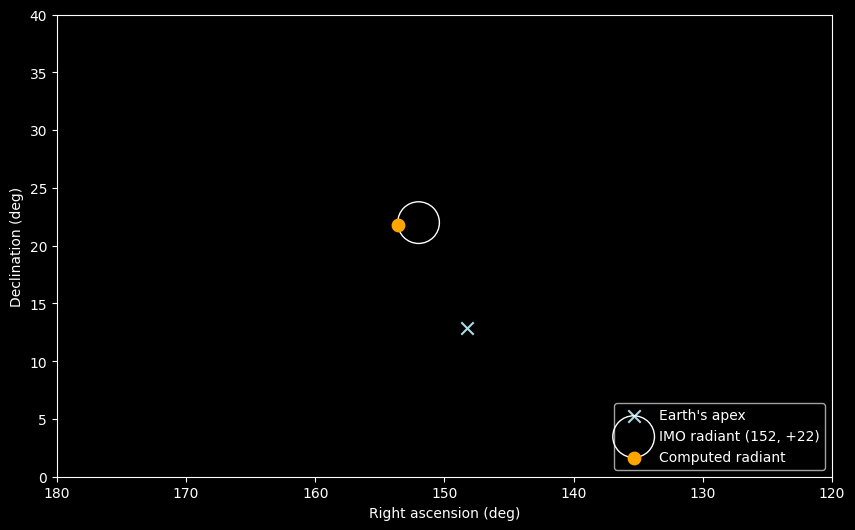

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(np.degrees(apex_ra_rad), np.degrees(apex_dec_rad), color='lightblue', marker='x', s=80, label="Earth's apex")
ax.scatter(152, 22, s=900, facecolors='none', edgecolors='white', label="IMO radiant (152, +22)")
ax.scatter(np.degrees(ra_rad), np.degrees(dec_rad), color='orange', s=80, label="Computed radiant")
ax.set_xlim(180, 120)
ax.set_ylim(0, 40)
ax.set_xlabel("Right ascension (deg)")
ax.set_ylabel("Declination (deg)")
ax.legend(loc='lower right')
plt.show()

## Take-Aways

* **From one orbit to one point in the sky:** with `conics`, `spkgeo`, `pxform` and `recrad`, the comet's orbit gives the Leonids' radiant at RA 153.6°, Dec +21.8°, within about 1.5° of the IMO's 152°, +22°.
* **Head-on and fast:** the grains move at about 41.5 km/s around the Sun, Earth at about 30 km/s, almost against each other. They meet at about 71 km/s, the fastest of the major annual showers (IMO).
* **What we left out:** the planets' pull on the dust over centuries, which shifts the trails (and decides whether the Leonids storm or trickle), and the bending of the meteors' paths by Earth's gravity close in ("zenith attraction"). An expert would add both; our simple picture still lands in the right spot.
* **Exercise:** the Geminids come from the asteroid 3200 Phaethon. Take its elements from the SBDB, use their maximum on December 14, 2026, at 13:49 UT, and compute their radiant and speed. The IMO lists RA 112°, Dec +33° and 35 km/s.

## Sources

* JPL Small-Body Database: 55P/Tempel-Tuttle, orbit J985/69. https://ssd.jpl.nasa.gov/tools/sbdb_lookup.html#/?sstr=55P
* Rendtel, J. (ed.) (2025): 2026 Meteor Shower Calendar. International Meteor Organization, IMO INFO(3-25). https://www.imo.net/files/meteor-shower/cal2026.pdf
* Jenniskens, P. (1995): Meteor stream activity. II. Meteor outbursts. Astronomy and Astrophysics 295, 206–235.
* NASA NAIF: generic kernels naif0012.tls and de440s.bsp. https://naif.jpl.nasa.gov/pub/naif/generic_kernels/
* Park, R. S., Folkner, W. M., Williams, J. G., & Boggs, D. H. (2021): The JPL Planetary and Lunar Ephemerides DE440 and DE441. The Astronomical Journal 161, 105. https://doi.org/10.3847/1538-3881/abd414
* Annex, A. M., Pearson, B., Seignovert, B., et al. (2020): SpiceyPy: a Pythonic Wrapper for the SPICE Toolkit. Journal of Open Source Software 5(46), 2050. https://doi.org/10.21105/joss.02050
* NASA Space Science Data Coordinated Archive: Earth Fact Sheet. https://nssdc.gsfc.nasa.gov/planetary/factsheet/earthfact.html